<a href="https://colab.research.google.com/github/Adamssbb/Deep-Learning-Based-NIDS-with-Built-in-Explanations/blob/main/xgboost_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [3]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
RAW_DIR = os.path.join(DATA_DIR, "raw")
RAW_DIR = os.path.join(DATA_DIR, "processed")
RAW_DIR = os.path.join(DATA_DIR, "explanations")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
NOTEBOOKS_DIR = os.path.join(PROJECT_DIR, "notebooks")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")
LOGS_DIR = os.path.join(PROJECT_DIR, "logs")
METRICS_DIR = os.path.join(PROJECT_DIR, "metrics")
# Check project folder
if os.path.isdir(PROJECT_DIR):
    print("Project directory found!")
else:
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_DIR}"
    )

print("\nProject path:", PROJECT_DIR)

Project directory found!

Project path: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai


In [5]:
import os

# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai"

# Correct raw data directory
RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")

# ZIP file path
ZIP_PATH = os.path.join(RAW_DIR, "MachineLearningCSV.zip")

# Verify ZIP file
print("Checking ZIP file...")
print("Expected path:", ZIP_PATH)

if os.path.isfile(ZIP_PATH):
    print("\nZIP file found successfully!")
    print("File:", ZIP_PATH)
    print("Size:", round(os.path.getsize(ZIP_PATH) / (1024**2), 2), "MB")
else:
    print("\nZIP file NOT found!")
    print("Checking contents of raw directory:")

    if os.path.isdir(RAW_DIR):
        print(os.listdir(RAW_DIR))
    else:
        print("Raw directory does not exist:", RAW_DIR)

Checking ZIP file...
Expected path: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/raw/MachineLearningCSV.zip

ZIP file found successfully!
File: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/raw/MachineLearningCSV.zip
Size: 224.21 MB


In [6]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    csv_files = [
        name for name in zip_ref.namelist()
        if name.lower().endswith(".csv")
    ]

    print("Total CSV files:", len(csv_files))

    for i, file in enumerate(csv_files, 1):
        print(f"{i}. {file}")

Total CSV files: 8
1. MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
2. MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
3. MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
4. MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
5. MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
6. MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
7. MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
8. MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [7]:
import os
import zipfile

EXTRACT_DIR = "/content/cicids2017_raw"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Extraction directory:", EXTRACT_DIR)

Dataset extracted successfully!
Extraction directory: /content/cicids2017_raw


In [8]:
import os

all_csv_files = []

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.lower().endswith(".csv"):
            all_csv_files.append(
                os.path.join(root, file)
            )

all_csv_files.sort()

print("Total extracted CSV files:", len(all_csv_files))

for i, file in enumerate(all_csv_files, 1):
    print(f"{i}. {os.path.basename(file)}")

Total extracted CSV files: 8
1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [10]:
import os

all_csv_files = []

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.lower().endswith(".csv"):
            all_csv_files.append(
                os.path.join(root, file)
            )

all_csv_files.sort()

print("Total extracted CSV files:", len(all_csv_files))

for i, file in enumerate(all_csv_files, 1):
    print(f"{i}. {os.path.basename(file)}")

Total extracted CSV files: 8
1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [11]:
import pandas as pd

if not all_csv_files:
    raise ValueError("No CSV files found!")

# Read first 1000 records
sample_df = pd.read_csv(
    all_csv_files[0],
    nrows=1000,
    low_memory=False
)

print("Dataset shape:", sample_df.shape)

print("\nTotal columns:", len(sample_df.columns))

print("\nColumn names:")
for i, col in enumerate(sample_df.columns, 1):
    print(f"{i}. {col}")

print("\nFirst 5 rows:")
display(sample_df.head())

Dataset shape: (1000, 79)

Total columns: 79

Column names:
1.  Destination Port
2.  Flow Duration
3.  Total Fwd Packets
4.  Total Backward Packets
5. Total Length of Fwd Packets
6.  Total Length of Bwd Packets
7.  Fwd Packet Length Max
8.  Fwd Packet Length Min
9.  Fwd Packet Length Mean
10.  Fwd Packet Length Std
11. Bwd Packet Length Max
12.  Bwd Packet Length Min
13.  Bwd Packet Length Mean
14.  Bwd Packet Length Std
15. Flow Bytes/s
16.  Flow Packets/s
17.  Flow IAT Mean
18.  Flow IAT Std
19.  Flow IAT Max
20.  Flow IAT Min
21. Fwd IAT Total
22.  Fwd IAT Mean
23.  Fwd IAT Std
24.  Fwd IAT Max
25.  Fwd IAT Min
26. Bwd IAT Total
27.  Bwd IAT Mean
28.  Bwd IAT Std
29.  Bwd IAT Max
30.  Bwd IAT Min
31. Fwd PSH Flags
32.  Bwd PSH Flags
33.  Fwd URG Flags
34.  Bwd URG Flags
35.  Fwd Header Length
36.  Bwd Header Length
37. Fwd Packets/s
38.  Bwd Packets/s
39.  Min Packet Length
40.  Max Packet Length
41.  Packet Length Mean
42.  Packet Length Std
43.  Packet Length Variance
44. FIN Flag

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [13]:
import os
import pandas as pd

file_info = []

for file in all_csv_files:

    df_header = pd.read_csv(
        file,
        nrows=0,
        encoding="utf-8-sig"
    )

    file_info.append({
        "File": os.path.basename(file),
        "Columns": len(df_header.columns),
        "Size (MB)": round(
            os.path.getsize(file) / (1024**2), 2
        )
    })

file_info_df = pd.DataFrame(file_info)

display(file_info_df)

# Verify column consistency after removing whitespace
column_sets = []

for file in all_csv_files:
    cols = pd.read_csv(
        file,
        nrows=0,
        encoding="utf-8-sig"
    ).columns.str.strip().tolist()

    column_sets.append(cols)

consistent = all(
    cols == column_sets[0]
    for cols in column_sets
)

print("\nColumn consistency:", consistent)

,File,Columns,Size (MB)
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,79,73.55
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,79,73.34
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,79,55.62
3,Monday-WorkingHours.pcap_ISCX.csv,79,168.73
4,Thursday-WorkingHours-Afternoon-Infilteration....,79,79.25
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,79,49.61
6,Tuesday-WorkingHours.pcap_ISCX.csv,79,128.82
7,Wednesday-workingHours.pcap_ISCX.csv,79,214.74



Column consistency: True


In [14]:
import os
import pandas as pd
import numpy as np

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Processed data directory:", PROCESSED_DIR)
print("Number of raw CSV files:", len(all_csv_files))

Processed data directory: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed
Number of raw CSV files: 8


In [15]:
def clean_cicids2017(df):

    # 1. Clean column names
    df.columns = df.columns.str.strip()

    # 2. Remove duplicate rows
    df = df.drop_duplicates().copy()

    # 3. Check label column
    if "Label" not in df.columns:
        raise ValueError("Label column not found!")

    # 4. Clean attack labels
    df["Label"] = (
        df["Label"]
        .astype("string")
        .str.strip()
    )

    # 5. Convert feature columns to numeric
    feature_cols = [
        col for col in df.columns
        if col != "Label"
    ]

    for col in feature_cols:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    # 6. Replace infinity
    df = df.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # 7. Remove rows with missing values
    df = df.dropna(
        subset=feature_cols + ["Label"]
    )

    # 8. Remove blank labels
    df = df[
        df["Label"].str.len().gt(0).fillna(False)
    ]

    return df.reset_index(drop=True)

print("Cleaning function created successfully!")

Cleaning function created successfully!


In [16]:
import gc

cleaned_files = []
cleaning_report = []

for file in all_csv_files:

    filename = os.path.basename(file)

    print("\nProcessing:", filename)

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding="utf-8-sig"
    )

    original_rows = len(df)

    df_clean = clean_cicids2017(df)

    cleaned_rows = len(df_clean)

    output_path = os.path.join(
        PROCESSED_DIR,
        filename
    )

    df_clean.to_csv(
        output_path,
        index=False
    )

    cleaned_files.append(output_path)

    cleaning_report.append({
        "File": filename,
        "Original Rows": original_rows,
        "Cleaned Rows": cleaned_rows,
        "Removed Rows": original_rows - cleaned_rows
    })

    print("Original rows:", original_rows)
    print("Cleaned rows:", cleaned_rows)
    print("Saved:", output_path)

    del df, df_clean
    gc.collect()

print("\nAll files processed successfully!")


Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Original rows: 225745
Cleaned rows: 223082
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Original rows: 286467
Cleaned rows: 213777
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Original rows: 191033
Cleaned rows: 184044
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Friday-WorkingHours-Morning.pcap_ISCX.csv

Processing: Monday-WorkingHours.pcap_ISCX.csv
Original rows: 529918
Cleaned rows: 502650
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Monday-WorkingHours.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Original ro

In [17]:
cleaning_report_df = pd.DataFrame(
    cleaning_report
)

display(cleaning_report_df)

print("\nTotal original rows:",
      cleaning_report_df["Original Rows"].sum())

print("Total cleaned rows:",
      cleaning_report_df["Cleaned Rows"].sum())

print("Total removed rows:",
      cleaning_report_df["Removed Rows"].sum())

,File,Original Rows,Cleaned Rows,Removed Rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,223082,2663
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,213777,72690
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,184044,6989
3,Monday-WorkingHours.pcap_ISCX.csv,529918,502650,27268
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,252790,35812
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,164179,6187
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,421626,24283
7,Wednesday-workingHours.pcap_ISCX.csv,692703,610492,82211



Total original rows: 2830743
Total cleaned rows: 2572640
Total removed rows: 258103


In [18]:
for file in cleaned_files:

    filename = os.path.basename(file)

    df_labels = pd.read_csv(
        file,
        usecols=["Label"]
    )

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    print(df_labels["Label"].value_counts())

    del df_labels
    gc.collect()


Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Label
BENIGN      123083
PortScan     90694
Name: count, dtype: int64

Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    182096
Bot         1948
Name: count, dtype: int64

Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    502650
Name: count, dtype: int64

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          252754
Infiltration        36
Name: count, dtype: int64

Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        162036
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         412476
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64

Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN        

In [19]:
import os
import pandas as pd
import gc

ENCODED_DIR = os.path.join(PROJECT_DIR, "data", "encoded")
os.makedirs(ENCODED_DIR, exist_ok=True)

encoded_files = []

for file in cleaned_files:

    filename = os.path.basename(file)
    print("Encoding:", filename)

    df = pd.read_csv(file, low_memory=False)

    df["Label"] = df["Label"].astype(str).str.strip()

    df["Binary_Label"] = (
        df["Label"] != "BENIGN"
    ).astype("int8")

    output_path = os.path.join(ENCODED_DIR, filename)
    df.to_csv(output_path, index=False)

    encoded_files.append(output_path)

    print(df["Binary_Label"].value_counts().sort_index())
    print()

    del df
    gc.collect()

print("Binary encoding completed!")

Encoding: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Binary_Label
0     95068
1    128014
Name: count, dtype: int64

Encoding: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Binary_Label
0    123083
1     90694
Name: count, dtype: int64

Encoding: Friday-WorkingHours-Morning.pcap_ISCX.csv
Binary_Label
0    182096
1      1948
Name: count, dtype: int64

Encoding: Monday-WorkingHours.pcap_ISCX.csv
Binary_Label
0    502650
Name: count, dtype: int64

Encoding: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Binary_Label
0    252754
1        36
Name: count, dtype: int64

Encoding: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Binary_Label
0    162036
1      2143
Name: count, dtype: int64

Encoding: Tuesday-WorkingHours.pcap_ISCX.csv
Binary_Label
0    412476
1      9150
Name: count, dtype: int64

Encoding: Wednesday-workingHours.pcap_ISCX.csv
Binary_Label
0    416736
1    193756
Name: count, dtype: int64

Binary encoding completed!


In [20]:
# Collect unique labels without combining datasets

unique_labels = set()

for file in encoded_files:
    labels = pd.read_csv(
        file,
        usecols=["Label"]
    )["Label"].dropna().unique()

    unique_labels.update(labels)

# Ensure BENIGN is class 0
attack_labels = sorted(
    label for label in unique_labels
    if label != "BENIGN"
)

label_mapping = {
    "BENIGN": 0,
    **{
        label: i
        for i, label in enumerate(attack_labels, start=1)
    }
}

print("Multiclass label mapping:")

for label, code in label_mapping.items():
    print(f"{code}: {label}")

Multiclass label mapping:
0: BENIGN
1: Bot
2: DDoS
3: DoS GoldenEye
4: DoS Hulk
5: DoS Slowhttptest
6: DoS slowloris
7: FTP-Patator
8: Heartbleed
9: Infiltration
10: PortScan
11: SSH-Patator
12: Web Attack � Brute Force
13: Web Attack � Sql Injection
14: Web Attack � XSS


In [21]:
import json

for file in encoded_files:

    print("Updating:", os.path.basename(file))

    df = pd.read_csv(file, low_memory=False)

    df["Multi_Label"] = (
        df["Label"]
        .map(label_mapping)
        .astype("int16")
    )

    df.to_csv(file, index=False)

    del df
    gc.collect()

mapping_path = os.path.join(
    ENCODED_DIR,
    "label_mapping.json"
)

with open(mapping_path, "w") as f:
    json.dump(label_mapping, f, indent=4)

print("\nMulticlass encoding completed!")
print("Mapping saved:", mapping_path)

Updating: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Updating: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Updating: Friday-WorkingHours-Morning.pcap_ISCX.csv
Updating: Monday-WorkingHours.pcap_ISCX.csv
Updating: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Updating: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Updating: Tuesday-WorkingHours.pcap_ISCX.csv
Updating: Wednesday-workingHours.pcap_ISCX.csv

Multiclass encoding completed!
Mapping saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/encoded/label_mapping.json


In [22]:
split_files = {
    "train": [],
    "validation": [],
    "test": []
}

for file in encoded_files:

    name = os.path.basename(file).lower()

    if name.startswith(("monday", "tuesday", "wednesday")):
        split_files["train"].append(file)

    elif name.startswith("thursday"):
        split_files["validation"].append(file)

    elif name.startswith("friday"):
        split_files["test"].append(file)

    else:
        raise ValueError(f"Unknown capture day: {name}")

for split_name, files in split_files.items():
    print(f"\n{split_name.upper()}:")
    for file in files:
        print(" -", os.path.basename(file))


TRAIN:
 - Monday-WorkingHours.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv

VALIDATION:
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

TEST:
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv


In [23]:
split_summary = []

for split_name, files in split_files.items():

    total_rows = 0
    benign_rows = 0
    attack_rows = 0

    for file in files:

        labels = pd.read_csv(
            file,
            usecols=["Binary_Label"]
        )["Binary_Label"]

        total_rows += len(labels)
        benign_rows += int((labels == 0).sum())
        attack_rows += int((labels == 1).sum())

    split_summary.append({
        "Split": split_name,
        "Total Rows": total_rows,
        "Benign": benign_rows,
        "Attack": attack_rows
    })

split_df = pd.DataFrame(split_summary)

split_df["Percentage"] = (
    split_df["Total Rows"]
    / split_df["Total Rows"].sum()
    * 100
).round(2)

display(split_df)

,Split,Total Rows,Benign,Attack,Percentage
0,train,1534768,1331862,202906,59.66
1,validation,416969,414790,2179,16.21
2,test,620903,400247,220656,24.13


In [24]:
import pandas as pd
import os

train_file = split_files["train"][0]

df_sample = pd.read_csv(
    train_file,
    nrows=1000,
    low_memory=False
)

excluded_columns = [
    "Label",
    "Binary_Label",
    "Multi_Label"
]

feature_cols = [
    col for col in df_sample.columns
    if col not in excluded_columns
]

print("Total feature columns:", len(feature_cols))
print("Features:")

for i, col in enumerate(feature_cols, 1):
    print(f"{i}. {col}")

Total feature columns: 78
Features:
1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Min Packet Length
40. Max Packet Length
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag Count
45. SYN Flag Count
46. RST Flag Count
47. PSH Flag Co

In [25]:
leakage_candidates = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Src IP",
    "Dst IP"
]

found_leakage_cols = [
    col for col in feature_cols
    if col.lower() in {
        name.lower() for name in leakage_candidates
    }
]

print("Potential leakage columns:", found_leakage_cols)

feature_cols = [
    col for col in feature_cols
    if col not in found_leakage_cols
]

print("Remaining feature count:", len(feature_cols))

Potential leakage columns: []
Remaining feature count: 78


In [26]:
import pandas as pd
import numpy as np

def collect_feature_hashes(files, feature_cols):

    hashes = set()

    for file in files:

        print("Checking:", os.path.basename(file))

        for chunk in pd.read_csv(
            file,
            usecols=feature_cols,
            chunksize=100000
        ):

            chunk = chunk[feature_cols]

            row_hashes = pd.util.hash_pandas_object(
                chunk,
                index=False
            ).to_numpy(dtype=np.uint64)

            hashes.update(row_hashes.tolist())

    return hashes


train_hashes = collect_feature_hashes(
    split_files["train"], feature_cols
)

validation_hashes = collect_feature_hashes(
    split_files["validation"], feature_cols
)

test_hashes = collect_feature_hashes(
    split_files["test"], feature_cols
)

print("\nTrain/Validation duplicate candidates:",
      len(train_hashes & validation_hashes))

print("Train/Test duplicate candidates:",
      len(train_hashes & test_hashes))

print("Validation/Test duplicate candidates:",
      len(validation_hashes & test_hashes))

Checking: Monday-WorkingHours.pcap_ISCX.csv
Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Checking: Wednesday-workingHours.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv

Train/Validation duplicate candidates: 14513
Train/Test duplicate candidates: 15236
Validation/Test duplicate candidates: 10966


In [27]:
for file in split_files["validation"]:

    df = pd.read_csv(
        file,
        usecols=["Label"]
    )

    print(os.path.basename(file))
    print(df["Label"].unique())

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
['BENIGN' 'Infiltration']
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
['BENIGN' 'Web Attack � Brute Force' 'Web Attack � XSS'
 'Web Attack � Sql Injection']


In [28]:
import pandas as pd
import os

web_file = next(
    f for f in all_csv_files
    if "WebAttacks" in os.path.basename(f)
)

df_web = pd.read_csv(
    web_file,
    usecols=lambda c: c.strip() == "Label",
    encoding="cp1252",
    low_memory=False
)

df_web.columns = df_web.columns.str.strip()

print(df_web["Label"].value_counts())
print("\nUnique labels:")
print(df_web["Label"].unique())

Label
BENIGN                          168186
Web Attack ï¿½ Brute Force        1507
Web Attack ï¿½ XSS                 652
Web Attack ï¿½ Sql Injection        21
Name: count, dtype: int64

Unique labels:
['BENIGN' 'Web Attack ï¿½ Brute Force' 'Web Attack ï¿½ XSS'
 'Web Attack ï¿½ Sql Injection']


In [29]:
import os

SPLIT_DIR = os.path.join(
    PROJECT_DIR, "data", "day_split"
)

os.makedirs(SPLIT_DIR, exist_ok=True)

for split in ["train", "validation", "test"]:
    os.makedirs(
        os.path.join(SPLIT_DIR, split),
        exist_ok=True
    )

print("Day-separated directories created.")

Day-separated directories created.


In [31]:
import pandas as pd
import numpy as np
import gc

def filter_partition(files, output_dir, excluded_hashes=None):

    if excluded_hashes is None:
        excluded_hashes = set()

    kept_hashes = set()
    report = []

    for file in files:

        filename = os.path.basename(file)
        output_path = os.path.join(output_dir, filename)

        total = 0
        removed = 0
        first_chunk = True

        for chunk in pd.read_csv(
            file,
            chunksize=100000,
            low_memory=False
        ):

            row_hashes = pd.util.hash_pandas_object(
                chunk[feature_cols],
                index=False
            ).to_numpy(dtype=np.uint64)

            # Exclude records matching earlier partitions
            keep_mask = np.array(
                [int(h) not in excluded_hashes for h in row_hashes],
                dtype=bool
            )

            filtered = chunk.loc[keep_mask]

            filtered.to_csv(
                output_path,
                mode="w" if first_chunk else "a",
                header=first_chunk,
                index=False
            )

            first_chunk = False

            total += len(chunk)
            removed += int((~keep_mask).sum())

            kept_hashes.update(
                row_hashes[keep_mask].tolist()
            )

        report.append({
            "File": filename,
            "Original Rows": total,
            "Removed": removed,
            "Remaining": total - removed
        })

        gc.collect()

    return kept_hashes, report

In [32]:
# Training: Monday–Wednesday
train_kept, train_report = filter_partition(
    split_files["train"],
    os.path.join(SPLIT_DIR, "train")
)

# Validation: Thursday, excluding training matches
val_kept, val_report = filter_partition(
    split_files["validation"],
    os.path.join(SPLIT_DIR, "validation"),
    excluded_hashes=train_kept
)

# Testing: Friday, excluding training and validation matches
test_kept, test_report = filter_partition(
    split_files["test"],
    os.path.join(SPLIT_DIR, "test"),
    excluded_hashes=train_kept | val_kept
)

print("Day-separated filtering completed!")

Day-separated filtering completed!


In [33]:
report_df = pd.DataFrame(
    train_report + val_report + test_report
)

display(report_df)

print("Total original rows:",
      report_df["Original Rows"].sum())

print("Total removed rows:",
      report_df["Removed"].sum())

print("Total remaining rows:",
      report_df["Remaining"].sum())

,File,Original Rows,Removed,Remaining
0,Monday-WorkingHours.pcap_ISCX.csv,502650,0,502650
1,Tuesday-WorkingHours.pcap_ISCX.csv,421626,0,421626
2,Wednesday-workingHours.pcap_ISCX.csv,610492,0,610492
3,Thursday-WorkingHours-Afternoon-Infilteration....,252790,9253,243537
4,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,164179,8037,156142
5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,223082,4842,218240
6,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,213777,8623,205154
7,Friday-WorkingHours-Morning.pcap_ISCX.csv,184044,11100,172944


Total original rows: 2572640
Total removed rows: 41855
Total remaining rows: 2530785


In [34]:
print(
    "Train/Validation overlap:",
    len(train_kept & val_kept)
)

print(
    "Train/Test overlap:",
    len(train_kept & test_kept)
)

print(
    "Validation/Test overlap:",
    len(val_kept & test_kept)
)

Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0


In [35]:
import os
import pandas as pd

for file in os.listdir(
    os.path.join(SPLIT_DIR, "validation")
):
    if "WebAttacks" in file:

        path = os.path.join(
            SPLIT_DIR, "validation", file
        )

        df = pd.read_csv(
            path,
            usecols=["Label"]
        )

        print(df["Label"].value_counts())

Label
BENIGN                        153999
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64


In [36]:
import os
import pandas as pd
import json

# Locate the Web Attacks file
web_file = os.path.join(
    SPLIT_DIR,
    "validation",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

df_web = pd.read_csv(web_file, low_memory=False)

# Normalize known Web Attack labels
def fix_web_label(label):
    label = str(label).strip()

    if label == "BENIGN":
        return "BENIGN"
    elif "Brute Force" in label:
        return "Web Attack Brute Force"
    elif "XSS" in label:
        return "Web Attack XSS"
    elif "Sql Injection" in label:
        return "Web Attack Sql Injection"
    else:
        return label

df_web["Label"] = df_web["Label"].apply(fix_web_label)

# Keep binary labels consistent
df_web["Binary_Label"] = (
    df_web["Label"] != "BENIGN"
).astype("int8")

print("Corrected labels:")
print(df_web["Label"].value_counts())

Corrected labels:
Label
BENIGN                      153999
Web Attack Brute Force        1470
Web Attack XSS                 652
Web Attack Sql Injection        21
Name: count, dtype: int64


In [37]:
# Read existing mapping
mapping_path = os.path.join(
    ENCODED_DIR,
    "label_mapping.json"
)

with open(mapping_path, "r") as f:
    old_mapping = json.load(f)

# Repair the mapping keys, preserving class IDs
new_mapping = {}

for label, class_id in old_mapping.items():
    corrected_label = fix_web_label(label)

    if corrected_label in new_mapping:
        raise ValueError(
            f"Duplicate mapping: {corrected_label}"
        )

    new_mapping[corrected_label] = class_id

# Verify every label can be encoded
if not df_web["Label"].isin(new_mapping).all():
    raise ValueError("Unmapped labels detected!")

df_web["Multi_Label"] = (
    df_web["Label"]
    .map(new_mapping)
    .astype("int16")
)

# Save corrected validation file
df_web.to_csv(web_file, index=False)

# Save corrected mapping
with open(mapping_path, "w") as f:
    json.dump(new_mapping, f, indent=4)

print("Corrected validation file saved!")
print("Multiclass mapping updated!")

print("\nUpdated mapping:")
for label, class_id in sorted(
    new_mapping.items(),
    key=lambda x: x[1]
):
    print(class_id, label)

Corrected validation file saved!
Multiclass mapping updated!

Updated mapping:
0 BENIGN
1 Bot
2 DDoS
3 DoS GoldenEye
4 DoS Hulk
5 DoS Slowhttptest
6 DoS slowloris
7 FTP-Patator
8 Heartbleed
9 Infiltration
10 PortScan
11 SSH-Patator
12 Web Attack Brute Force
13 Web Attack Sql Injection
14 Web Attack XSS


In [38]:
df_check = pd.read_csv(
    web_file,
    usecols=["Label", "Binary_Label", "Multi_Label"]
)

print("Final label distribution:")
print(df_check["Label"].value_counts())

print("\nBinary distribution:")
print(df_check["Binary_Label"].value_counts())

print("\nMulticlass distribution:")
print(
    df_check.groupby(
        ["Multi_Label", "Label"]
    ).size()
)

print("\nCorrupted labels remaining:",
      df_check["Label"].str.contains(
          "\uFFFD", regex=False
      ).sum())

Final label distribution:
Label
BENIGN                      153999
Web Attack Brute Force        1470
Web Attack XSS                 652
Web Attack Sql Injection        21
Name: count, dtype: int64

Binary distribution:
Binary_Label
0    153999
1      2143
Name: count, dtype: int64

Multiclass distribution:
Multi_Label  Label                   
0            BENIGN                      153999
12           Web Attack Brute Force        1470
13           Web Attack Sql Injection        21
14           Web Attack XSS                 652
dtype: int64

Corrupted labels remaining: 0


In [39]:
!pip -q install xgboost scikit-learn joblib

In [40]:
import os
import time
import json
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [41]:
def load_split(split_name):

    folder = os.path.join(SPLIT_DIR, split_name)

    files = sorted([
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(".csv")
    ])

    if not files:
        raise ValueError(f"No CSV files found in {folder}")

    frames = []

    for file in files:
        print("Loading:", os.path.basename(file))
        frames.append(pd.read_csv(file, low_memory=False))

    return pd.concat(frames, ignore_index=True)


train_df = load_split("train")
val_df = load_split("validation")
test_df = load_split("test")

print("\nTrain:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv

Train: (1534768, 81)
Validation: (399679, 81)
Test: (596338, 81)


In [42]:
excluded_columns = [
    "Label",
    "Binary_Label",
    "Multi_Label"
]

feature_cols = [
    col for col in train_df.columns
    if col not in excluded_columns
]

# Exclude known identifier columns if present
leakage_columns = {
    "flow id",
    "source ip",
    "destination ip",
    "src ip",
    "dst ip",
    "timestamp"
}

feature_cols = [
    col for col in feature_cols
    if col.lower() not in leakage_columns
]

X_train = train_df[feature_cols].astype("float32")
X_val = val_df[feature_cols].astype("float32")
X_test = test_df[feature_cols].astype("float32")

y_train = train_df["Binary_Label"].astype("int8")
y_val = val_df["Binary_Label"].astype("int8")
y_test = test_df["Binary_Label"].astype("int8")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Features:", len(feature_cols))

Training: (1534768, 78)
Validation: (399679, 78)
Testing: (596338, 78)
Features: 78


In [43]:
for name, X in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    values = X.to_numpy()

    print(
        name,
        "NaN:", np.isnan(values).sum(),
        "Infinity:", np.isinf(values).sum()
    )

Train NaN: 0 Infinity: 0
Validation NaN: 0 Infinity: 0
Test NaN: 0 Infinity: 0


In [44]:
benign_count = int((y_train == 0).sum())
attack_count = int((y_train == 1).sum())

scale_pos_weight = benign_count / attack_count

print("Benign:", benign_count)
print("Attack:", attack_count)
print("Scale positive weight:", round(scale_pos_weight, 4))

Benign: 1331862
Attack: 202906
Scale positive weight: 6.5639


In [45]:
start_time = time.time()

model = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

training_time = time.time() - start_time

print("\nTraining completed!")
print("Training time:", round(training_time, 2), "seconds")
print("Best iteration:", model.best_iteration)

[0]	validation_0-logloss:0.64729
[50]	validation_0-logloss:0.06484
[100]	validation_0-logloss:0.02541
[150]	validation_0-logloss:0.01918
[200]	validation_0-logloss:0.00971
[250]	validation_0-logloss:0.00705
[300]	validation_0-logloss:0.00564
[350]	validation_0-logloss:0.00493
[400]	validation_0-logloss:0.00481
[450]	validation_0-logloss:0.00476
[465]	validation_0-logloss:0.00478

Training completed!
Training time: 299.45 seconds
Best iteration: 435


In [46]:
def evaluate_binary(model, X, y, name):

    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results = {
        "Dataset": name,
        "Macro F1": f1_score(y, predictions, average="macro"),
        "Weighted F1": f1_score(y, predictions, average="weighted"),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities)
    }

    print(f"\n{name} Classification Report:")
    print(classification_report(y, predictions, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y, predictions))

    return results


val_results = evaluate_binary(
    model, X_val, y_val, "Validation"
)

test_results = evaluate_binary(
    model, X_test, y_test, "Test"
)

results_df = pd.DataFrame([
    val_results,
    test_results
])

display(results_df)


Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    397500
           1       0.95      0.86      0.91      2179

    accuracy                           1.00    399679
   macro avg       0.98      0.93      0.95    399679
weighted avg       1.00      1.00      1.00    399679

Confusion Matrix:
[[397411     89]
 [   303   1876]]

Test Classification Report:
              precision    recall  f1-score   support

           0       0.65      1.00      0.79    376248
           1       1.00      0.06      0.12    220090

    accuracy                           0.65    596338
   macro avg       0.82      0.53      0.45    596338
weighted avg       0.78      0.65      0.54    596338

Confusion Matrix:
[[376199     49]
 [205964  14126]]


,Dataset,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,Validation,0.952456,0.998994,0.954707,0.860945,0.993509,0.919305
1,Test,0.452823,0.539820,0.996543,0.064183,0.788191,0.807211


In [47]:
test_predictions = model.predict(X_test)

attack_results = test_df[["Label", "Binary_Label"]].copy()
attack_results["Prediction"] = test_predictions

attack_recall = (
    attack_results[attack_results["Binary_Label"] == 1]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

attack_recall["Recall"] = (
    attack_recall["Detected"] / attack_recall["Total"]
)

display(attack_recall)

,Total,Detected,Recall
Label,,,
Bot,1948,0,0.000000
DDoS,128012,13850,0.108193
PortScan,90130,276,0.003062


In [49]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

model.save_model(
    os.path.join(MODEL_DIR, "xgboost_binary.json")
)

results_df.to_csv(
    os.path.join(RESULT_DIR, "xgboost_binary_metrics.csv"),
    index=False
)

attack_recall.to_csv(
    os.path.join(RESULT_DIR, "xgboost_binary_attack_recall.csv")
)

joblib.dump(
    feature_cols,
    os.path.join(MODEL_DIR, "xgboost_feature_columns.pkl")
)

print("Model and evaluation results saved successfully!")

Model and evaluation results saved successfully!


In [50]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    f1_score
)

val_prob = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Best validation attack F1 threshold:", best_threshold)
print("Best validation attack F1:", f1_values[best_index])

Best validation attack F1 threshold: 0.082179375
Best validation attack F1: 0.9221111369443966


In [51]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

test_prob = model.predict_proba(X_test)[:, 1]

test_pred_tuned = (
    test_prob >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)

print("\nTest classification report:")
print(
    classification_report(
        y_test,
        test_pred_tuned,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_pred_tuned))

print("\nMacro-F1:",
      f1_score(y_test, test_pred_tuned, average="macro"))

print("Attack precision:",
      precision_score(y_test, test_pred_tuned, zero_division=0))

print("Attack recall:",
      recall_score(y_test, test_pred_tuned, zero_division=0))

Selected threshold: 0.082179375

Test classification report:
              precision    recall  f1-score   support

           0       0.72      1.00      0.84    376248
           1       1.00      0.35      0.52    220090

    accuracy                           0.76    596338
   macro avg       0.86      0.67      0.68    596338
weighted avg       0.83      0.76      0.72    596338


Confusion matrix:
[[376146    102]
 [143642  76448]]

Macro-F1: 0.6775019899103203
Attack precision: 0.9986675375571522
Attack recall: 0.34734881184969785


In [52]:
original_pred = (test_prob >= 0.5).astype(int)

comparison = pd.DataFrame([
    {
        "Threshold": 0.5,
        "Macro-F1": f1_score(
            y_test, original_pred, average="macro"
        ),
        "Precision": precision_score(
            y_test, original_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, original_pred, zero_division=0
        )
    },
    {
        "Threshold": float(best_threshold),
        "Macro-F1": f1_score(
            y_test, test_pred_tuned, average="macro"
        ),
        "Precision": precision_score(
            y_test, test_pred_tuned, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred_tuned, zero_division=0
        )
    }
], index=["Default", "Validation-tuned"])

display(comparison)

,Threshold,Macro-F1,Precision,Recall
Default,0.500000,0.452823,0.996543,0.064183
Validation-tuned,0.082179,0.677502,0.998668,0.347349


In [53]:
import os
import json
import pandas as pd

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

final_metrics = {
    "Model": "XGBoost",
    "Task": "Binary",
    "Split": "Day-separated",
    "Threshold": float(best_threshold),
    "Macro_F1": 0.6775019891,
    "Precision": 0.9986675376,
    "Recall": 0.3473488118,
    "ROC_AUC": 0.788191,
    "PR_AUC": 0.807211
}

pd.DataFrame([final_metrics]).to_csv(
    os.path.join(RESULT_DIR, "xgboost_binary_tuned_metrics.csv"),
    index=False
)

with open(
    os.path.join(RESULT_DIR, "xgboost_binary_threshold.json"),
    "w"
) as f:
    json.dump(
        {"threshold": float(best_threshold)},
        f,
        indent=4
    )

print("Tuned XGBoost results saved successfully!")

Tuned XGBoost results saved successfully!


In [54]:
import pandas as pd

attack_results_tuned = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_tuned["Prediction"] = test_pred_tuned

attack_recall_tuned = (
    attack_results_tuned[
        attack_results_tuned["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

attack_recall_tuned["Recall"] = (
    attack_recall_tuned["Detected"]
    / attack_recall_tuned["Total"]
)

print("Per-attack-type recall after threshold tuning:")
display(attack_recall_tuned)

attack_recall_tuned.to_csv(
    os.path.join(
        RESULT_DIR,
        "xgboost_binary_tuned_attack_recall.csv"
    )
)

Per-attack-type recall after threshold tuning:


,Total,Detected,Recall
Label,,,
Bot,1948,0,0.000000
DDoS,128012,75443,0.589343
PortScan,90130,1005,0.011151


In [55]:
from sklearn.preprocessing import StandardScaler
import joblib
import numpy as np
import os

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(
    X_train
).astype(np.float32)

# Apply same scaler to validation and test
X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test
).astype(np.float32)

# Save scaler
joblib.dump(
    scaler,
    os.path.join(
        PROJECT_DIR,
        "models",
        "standard_scaler.pkl"
    )
)

print("Scaling completed!")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("NaN in training:",
      np.isnan(X_train_scaled).sum())

print("Infinity in training:",
      np.isinf(X_train_scaled).sum())

Scaling completed!
Training: (1534768, 78)
Validation: (399679, 78)
Testing: (596338, 78)
NaN in training: 0
Infinity in training: 0


In [56]:
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_val_cnn = X_val_scaled.reshape(
    X_val_scaled.shape[0],
    X_val_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("CNN Training:", X_train_cnn.shape)
print("CNN Validation:", X_val_cnn.shape)
print("CNN Testing:", X_test_cnn.shape)

CNN Training: (1534768, 78, 1)
CNN Validation: (399679, 78, 1)
CNN Testing: (596338, 78, 1)


In [57]:
import tensorflow as tf
import numpy as np
import pandas as pd
import time
import os

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow version:", tf.__version__)

print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: []


In [58]:
cnn_model = Sequential([

    Input(shape=(78, 1)),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dropout(0.2),

    Dense(1, activation="sigmoid")

])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 78, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 78, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 39, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 39, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 39, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 19, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2432)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       311,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,473 (1.32 MB)

 Trainable params: 345,089 (1.32 MB)

 Non-trainable params: 384 (1.50 KB)

In [59]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("1D-CNN model compiled successfully!")

1D-CNN model compiled successfully!


In [64]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.asarray(y_train)
)

class_weights = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("Class weights:", class_weights)

Class weights: {0: 0.5761738077969039, 1: 3.7819680048889635}


In [65]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

cnn_path = os.path.join(
    MODEL_DIR,
    "cnn_binary_best.keras"
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=cnn_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )

]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [66]:
start_time = time.time()

cnn_history = cnn_model.fit(

    X_train_cnn,
    np.asarray(y_train),

    validation_data=(
        X_val_cnn,
        np.asarray(y_val)
    ),

    epochs=30,

    batch_size=1024,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)

cnn_training_time = time.time() - start_time

print("\nCNN training completed!")

print(
    "Training time:",
    round(cnn_training_time, 2),
    "seconds"
)

print(
    "Epochs completed:",
    len(cnn_history.history["loss"])
)

Epoch 1/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 665s 443ms/step - accuracy: 0.9838 - auc: 0.9992 - loss: 0.0299 - precision: 0.8939 - recall: 0.9952 - val_accuracy: 0.9739 - val_auc: 0.8894 - val_loss: 0.0965 - val_precision: 0.0181 - val_recall: 0.0711 - learning_rate: 0.0010
Epoch 2/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 640s 427ms/step - accuracy: 0.9916 - auc: 0.9996 - loss: 0.0175 - precision: 0.9420 - recall: 0.9980 - val_accuracy: 0.9231 - val_auc: 0.9183 - val_loss: 0.2073 - val_precision: 0.0619 - val_recall: 0.9257 - learning_rate: 0.0010
Epoch 3/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 647s 431ms/step - accuracy: 0.9931 - auc: 0.9997 - loss: 0.0145 - precision: 0.9517 - recall: 0.9984 - val_accuracy: 0.9708 - val_auc: 0.9219 - val_loss: 0.0976 - val_precision: 0.0152 - val_recall: 0.0684 - learning_rate: 0.0010
Epoch 4/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 682s 431ms/step - accuracy: 0.9939 - auc: 0.9997 - loss: 0.0124 - precision: 0.9566 - recall: 0.9988 - val_accuracy: 0.9905 - val_auc: 0.5575 

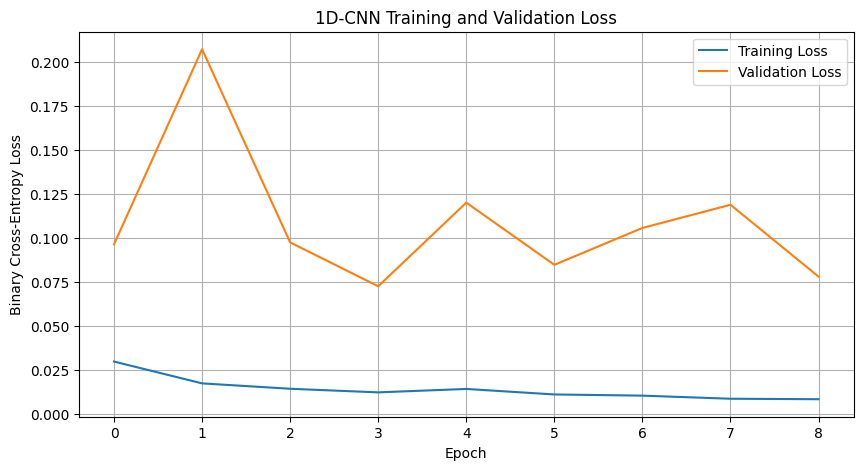

In [67]:
import matplotlib.pyplot as plt

history = cnn_history.history

plt.figure(figsize=(10, 5))

plt.plot(
    history["loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.title("1D-CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

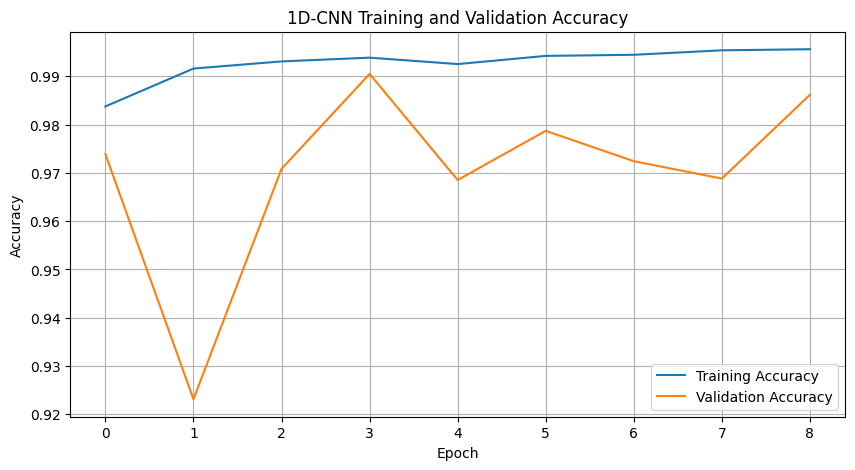

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("1D-CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [69]:
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

history_df = pd.DataFrame(cnn_history.history)

history_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_training_history.csv"
    ),
    index=False
)

print("CNN training history saved!")

CNN training history saved!


In [70]:
import os
import tensorflow as tf

cnn_path = os.path.join(
    PROJECT_DIR,
    "models",
    "cnn_binary_best.keras"
)

cnn_best = tf.keras.models.load_model(cnn_path)

print("Best CNN model loaded successfully!")
cnn_best.summary()

Best CNN model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 78, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 78, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 39, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 39, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 39, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 19, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2432)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       311,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035,653 (3.95 MB)

 Trainable params: 345,089 (1.32 MB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 690,180 (2.63 MB)

In [71]:
import numpy as np

val_prob_cnn = cnn_best.predict(
    X_val_cnn,
    batch_size=2048,
    verbose=1
).ravel()

print("Validation probabilities shape:", val_prob_cnn.shape)

print("Minimum probability:", val_prob_cnn.min())
print("Maximum probability:", val_prob_cnn.max())

196/196 ━━━━━━━━━━━━━━━━━━━━ 33s 168ms/step
Validation probabilities shape: (399679,)
Minimum probability: 0.0
Maximum probability: 0.9999923


In [72]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

val_pred_default = (
    val_prob_cnn >= 0.5
).astype(int)

print("CNN Validation Classification Report:")
print(
    classification_report(
        y_val,
        val_pred_default,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, val_pred_default))

print("Macro-F1:",
      f1_score(y_val, val_pred_default, average="macro"))

print("ROC-AUC:",
      roc_auc_score(y_val, val_prob_cnn))

print("PR-AUC:",
      average_precision_score(y_val, val_prob_cnn))

CNN Validation Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00    397500
           1       0.06      0.05      0.05      2179

    accuracy                           0.99    399679
   macro avg       0.53      0.52      0.52    399679
weighted avg       0.99      0.99      0.99    399679

Confusion Matrix:
[[395775   1725]
 [  2072    107]]
Macro-F1: 0.5242896308042577
ROC-AUC: 0.954816300824624
PR-AUC: 0.0929552899098577


In [73]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob_cnn
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)

cnn_best_threshold = float(thresholds[best_index])

print("Best CNN threshold:", cnn_best_threshold)
print("Best validation attack F1:", f1_scores[best_index])

Best CNN threshold: 0.0025612066965550184
Best validation attack F1: 0.2626788036408491


In [74]:
test_prob_cnn = cnn_best.predict(
    X_test_cnn,
    batch_size=2048,
    verbose=1
).ravel()

test_pred_cnn_default = (
    test_prob_cnn >= 0.5
).astype(int)

test_pred_cnn_tuned = (
    test_prob_cnn >= cnn_best_threshold
).astype(int)

print("CNN TEST RESULTS — DEFAULT THRESHOLD")
print(
    classification_report(
        y_test,
        test_pred_cnn_default,
        zero_division=0
    )
)

print("CNN TEST RESULTS — TUNED THRESHOLD")
print(
    classification_report(
        y_test,
        test_pred_cnn_tuned,
        zero_division=0
    )
)

print("Tuned confusion matrix:")
print(confusion_matrix(y_test, test_pred_cnn_tuned))

292/292 ━━━━━━━━━━━━━━━━━━━━ 50s 170ms/step
CNN TEST RESULTS — DEFAULT THRESHOLD
              precision    recall  f1-score   support

           0       0.72      1.00      0.84    376248
           1       0.98      0.35      0.52    220090

    accuracy                           0.76    596338
   macro avg       0.85      0.67      0.68    596338
weighted avg       0.82      0.76      0.72    596338

CNN TEST RESULTS — TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.74      0.98      0.84    376248
           1       0.91      0.40      0.56    220090

    accuracy                           0.76    596338
   macro avg       0.82      0.69      0.70    596338
weighted avg       0.80      0.76      0.74    596338

Tuned confusion matrix:
[[367831   8417]
 [132019  88071]]


In [75]:
import pandas as pd

def cnn_metrics(y_true, y_pred, probabilities, threshold_name):

    return {
        "Model": "1D-CNN",
        "Threshold": threshold_name,
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted"
        ),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }

cnn_results = pd.DataFrame([
    cnn_metrics(
        y_test,
        test_pred_cnn_default,
        test_prob_cnn,
        "Default 0.5"
    ),
    cnn_metrics(
        y_test,
        test_pred_cnn_tuned,
        test_prob_cnn,
        f"Tuned {cnn_best_threshold:.6f}"
    )
])

display(cnn_results)

,Model,Threshold,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,1D-CNN,Default 0.5,0.677834,0.719862,0.977806,0.351711,0.755375,0.748061
1,1D-CNN,Tuned 0.002561,0.698048,0.735142,0.912766,0.400159,0.755375,0.748061


In [76]:
attack_results_cnn = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_cnn["Prediction"] = test_pred_cnn_tuned

cnn_attack_recall = (
    attack_results_cnn[
        attack_results_cnn["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

cnn_attack_recall["Recall"] = (
    cnn_attack_recall["Detected"]
    / cnn_attack_recall["Total"]
)

display(cnn_attack_recall)

,Total,Detected,Recall
Label,,,
Bot,1948,0,0.000000
DDoS,128012,81349,0.635479
PortScan,90130,6722,0.074581


In [77]:
import json

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

cnn_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_metrics.csv"
    ),
    index=False
)

cnn_attack_recall.to_csv(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_attack_recall.csv"
    )
)

with open(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_threshold.json"
    ),
    "w"
) as f:
    json.dump(
        {"threshold": cnn_best_threshold},
        f,
        indent=4
    )

print("CNN evaluation results saved successfully!")

CNN evaluation results saved successfully!


In [78]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import os

def compare_model(name, predictions, probabilities):
    return {
        "Model": name,
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    }

comparison_df = pd.DataFrame([
    compare_model(
        "XGBoost",
        test_pred_tuned,
        test_prob
    ),
    compare_model(
        "1D-CNN",
        test_pred_cnn_tuned,
        test_prob_cnn
    )
])

display(comparison_df)

comparison_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results",
        "xgboost_vs_cnn_binary.csv"
    ),
    index=False
)

print("Comparison saved successfully!")

,Model,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBoost,0.677502,0.719943,0.998668,0.347349,0.788191,0.807211
1,1D-CNN,0.698048,0.735142,0.912766,0.400159,0.755375,0.748061


Comparison saved successfully!


In [79]:
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: []


In [80]:
X_train_lstm = X_train_cnn
X_val_lstm = X_val_cnn
X_test_lstm = X_test_cnn

print("LSTM Training:", X_train_lstm.shape)
print("LSTM Validation:", X_val_lstm.shape)
print("LSTM Testing:", X_test_lstm.shape)

assert X_train_lstm.shape[1:] == (78, 1)
assert X_val_lstm.shape[1:] == (78, 1)
assert X_test_lstm.shape[1:] == (78, 1)

LSTM Training: (1534768, 78, 1)
LSTM Validation: (399679, 78, 1)
LSTM Testing: (596338, 78, 1)


In [81]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout
)

lstm_model = Sequential([
    Input(shape=(78, 1)),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        1,
        activation="sigmoid"
    )
])

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("LSTM model compiled successfully!")

LSTM model compiled successfully!


In [84]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

lstm_path = os.path.join(
    MODEL_DIR,
    "lstm_binary_best.keras"
)

lstm_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=lstm_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

In [85]:
import time

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_lstm,
    np.asarray(y_train),

    validation_data=(
        X_val_lstm,
        np.asarray(y_val)
    ),

    epochs=20,
    batch_size=1024,

    class_weight=class_weights,

    callbacks=lstm_callbacks,
    verbose=1
)

lstm_training_time = time.time() - start_time

print("\nLSTM training completed!")
print("Training time:", round(lstm_training_time, 2), "seconds")
print("Epochs completed:", len(lstm_history.history["loss"]))

Epoch 1/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 321s 213ms/step - accuracy: 0.9459 - auc: 0.9526 - loss: 0.2373 - precision: 0.7630 - recall: 0.8576 - val_accuracy: 0.8466 - val_auc: 0.7609 - val_loss: 0.1998 - val_precision: 0.0025 - val_recall: 0.0688 - learning_rate: 0.0010
Epoch 2/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 316s 211ms/step - accuracy: 0.9430 - auc: 0.9925 - loss: 0.1031 - precision: 0.7074 - recall: 0.9701 - val_accuracy: 0.8860 - val_auc: 0.8087 - val_loss: 0.1801 - val_precision: 0.0016 - val_recall: 0.0321 - learning_rate: 0.0010
Epoch 3/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 313s 209ms/step - accuracy: 0.9590 - auc: 0.9956 - loss: 0.0779 - precision: 0.7699 - recall: 0.9839 - val_accuracy: 0.9119 - val_auc: 0.7781 - val_loss: 0.1772 - val_precision: 0.0020 - val_recall: 0.0303 - learning_rate: 0.0010
Epoch 4/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 313s 209ms/step - accuracy: 0.9620 - auc: 0.9963 - loss: 0.0698 - precision: 0.7824 - recall: 0.9877 - val_accuracy: 0.8851 - val_auc: 0.6978 

In [86]:
import pandas as pd

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

lstm_history_df = pd.DataFrame(lstm_history.history)

lstm_history_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_training_history.csv"
    ),
    index=False
)

print("LSTM training history saved!")

LSTM training history saved!


In [87]:
import os
import tensorflow as tf

lstm_path = os.path.join(
    PROJECT_DIR,
    "models",
    "lstm_binary_best.keras"
)

lstm_best = tf.keras.models.load_model(lstm_path)

print("Best LSTM model loaded successfully!")
lstm_best.summary()

Best LSTM model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,325 (63.77 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,884 (42.52 KB)

In [88]:
import numpy as np

val_prob_lstm = lstm_best.predict(
    X_val_lstm,
    batch_size=2048,
    verbose=1
).ravel()

print("Validation probability shape:", val_prob_lstm.shape)

print("Minimum:", val_prob_lstm.min())
print("Maximum:", val_prob_lstm.max())
print("Mean:", val_prob_lstm.mean())

196/196 ━━━━━━━━━━━━━━━━━━━━ 37s 186ms/step
Validation probability shape: (399679,)
Minimum: 1.8988322e-07
Maximum: 0.9999987
Mean: 0.011739483


In [89]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    average_precision_score
)

val_pred_lstm_default = (
    val_prob_lstm >= 0.5
).astype(int)

print("LSTM VALIDATION CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        val_pred_lstm_default,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_lstm_default))

print("\nMacro-F1:",
      f1_score(
          y_val,
          val_pred_lstm_default,
          average="macro"
      ))

print("ROC-AUC:",
      roc_auc_score(y_val, val_prob_lstm))

print("PR-AUC:",
      average_precision_score(y_val, val_prob_lstm))

LSTM VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    397500
           1       0.01      0.02      0.01      2179

    accuracy                           0.99    399679
   macro avg       0.50      0.50      0.50    399679
weighted avg       0.99      0.99      0.99    399679


Confusion Matrix:
[[393874   3626]
 [  2144     35]]

Macro-F1: 0.5023574423582143
ROC-AUC: 0.8188631846008642
PR-AUC: 0.014928928801697655


In [90]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob_lstm
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)

lstm_best_threshold = float(
    thresholds[best_index]
)

print("Best LSTM threshold:", lstm_best_threshold)

print("Best validation attack F1:",
      f1_scores[best_index])

Best LSTM threshold: 0.00032960265525616705
Best validation attack F1: 0.051215203752156394


In [91]:
test_prob_lstm = lstm_best.predict(
    X_test_lstm,
    batch_size=2048,
    verbose=1
).ravel()

test_pred_lstm_default = (
    test_prob_lstm >= 0.5
).astype(int)

test_pred_lstm_tuned = (
    test_prob_lstm >= lstm_best_threshold
).astype(int)

print("LSTM TEST — DEFAULT THRESHOLD")

print(
    classification_report(
        y_test,
        test_pred_lstm_default,
        zero_division=0
    )
)

print("\nLSTM TEST — TUNED THRESHOLD")

print(
    classification_report(
        y_test,
        test_pred_lstm_tuned,
        zero_division=0
    )
)

print("\nTuned Confusion Matrix:")
print(confusion_matrix(y_test, test_pred_lstm_tuned))

292/292 ━━━━━━━━━━━━━━━━━━━━ 54s 185ms/step
LSTM TEST — DEFAULT THRESHOLD
              precision    recall  f1-score   support

           0       0.73      0.99      0.84    376248
           1       0.97      0.37      0.54    220090

    accuracy                           0.76    596338
   macro avg       0.85      0.68      0.69    596338
weighted avg       0.82      0.76      0.73    596338


LSTM TEST — TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.89      0.84      0.86    376248
           1       0.75      0.83      0.79    220090

    accuracy                           0.83    596338
   macro avg       0.82      0.83      0.82    596338
weighted avg       0.84      0.83      0.83    596338


Tuned Confusion Matrix:
[[315125  61123]
 [ 38316 181774]]


In [92]:
attack_results_lstm = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_lstm["Prediction"] = test_pred_lstm_tuned

lstm_attack_recall = (
    attack_results_lstm[
        attack_results_lstm["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

lstm_attack_recall["Recall"] = (
    lstm_attack_recall["Detected"]
    / lstm_attack_recall["Total"]
)

display(lstm_attack_recall)

,Total,Detected,Recall
Label,,,
Bot,1948,952,0.488706
DDoS,128012,124866,0.975424
PortScan,90130,55956,0.620837


In [98]:

import pandas as pd
import numpy as np
import os
import json

from IPython.display import display

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

# Function to evaluate LSTM binary classification
def evaluate_lstm(y_true, y_pred, probabilities, threshold_name):

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    probabilities = np.asarray(probabilities).ravel()

    return {
        "Model": "LSTM",
        "Task": "Binary",
        "Threshold": threshold_name,

        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "ROC-AUC": (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2 else np.nan
        ),

        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


# Evaluate default and tuned thresholds
lstm_results = pd.DataFrame([
    evaluate_lstm(
        y_test,
        test_pred_lstm_default,
        test_prob_lstm,
        "Default 0.5"
    ),

    evaluate_lstm(
        y_test,
        test_pred_lstm_tuned,
        test_prob_lstm,
        f"Tuned {lstm_best_threshold:.8f}"
    )
])

# Display results
print("LSTM Evaluation Results:")
display(lstm_results.round(4))


LSTM Evaluation Results:


,Model,Task,Threshold,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,LSTM,Binary,Default 0.5,0.6895,0.7293,0.9675,0.3723,0.8599,0.8566
1,LSTM,Binary,Tuned 0.00032960,0.8245,0.8348,0.7484,0.8259,0.8599,0.8566


In [99]:
attack_results_lstm = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_lstm["Prediction"] = test_pred_lstm_tuned

lstm_attack_recall = (
    attack_results_lstm[
        attack_results_lstm["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

lstm_attack_recall["Recall"] = (
    lstm_attack_recall["Detected"]
    / lstm_attack_recall["Total"]
)

print("LSTM per-attack-type recall:")
display(lstm_attack_recall)

LSTM per-attack-type recall:


,Total,Detected,Recall
Label,,,
Bot,1948,952,0.488706
DDoS,128012,124866,0.975424
PortScan,90130,55956,0.620837


In [100]:
import os
import json

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# Save LSTM classification metrics
lstm_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_metrics.csv"
    ),
    index=False
)

# Save LSTM per-attack-type recall
lstm_attack_recall.to_csv(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_attack_recall.csv"
    )
)

# Save optimized LSTM threshold
with open(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_threshold.json"
    ),
    "w"
) as f:
    json.dump(
        {"threshold": float(lstm_best_threshold)},
        f,
        indent=4
    )

print("LSTM evaluation results saved successfully!")

print("\nSaved files:")
print(os.listdir(RESULT_DIR))

LSTM evaluation results saved successfully!

Saved files:
['metrics', 'figures', 'logs', 'xgboost_binary_metrics.csv', 'xgboost_binary_attack_recall.csv', 'xgboost_binary_tuned_metrics.csv', 'xgboost_binary_threshold.json', 'xgboost_binary_tuned_attack_recall.csv', 'cnn_binary_training_history.csv', 'cnn_binary_metrics.csv', 'cnn_binary_attack_recall.csv', 'cnn_binary_threshold.json', 'xgboost_vs_cnn_binary.csv', 'lstm_binary_training_history.csv', 'lstm_binary_metrics.csv', 'lstm_binary_attack_recall.csv', 'lstm_binary_threshold.json']


In [101]:
files_to_check = [
    "lstm_binary_metrics.csv",
    "lstm_binary_attack_recall.csv",
    "lstm_binary_threshold.json"
]

for filename in files_to_check:
    path = os.path.join(RESULT_DIR, filename)

    if os.path.isfile(path):
        print("SUCCESS:", filename)
    else:
        print("MISSING:", filename)

SUCCESS: lstm_binary_metrics.csv
SUCCESS: lstm_binary_attack_recall.csv
SUCCESS: lstm_binary_threshold.json


In [102]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

print("LSTM TEST REPORT — TUNED THRESHOLD")

print(
    classification_report(
        y_test,
        test_pred_lstm_tuned,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred_lstm_tuned))

print("\nMacro-F1:",
      f1_score(y_test, test_pred_lstm_tuned, average="macro"))

print("Attack precision:",
      precision_score(y_test, test_pred_lstm_tuned, zero_division=0))

print("Attack recall:",
      recall_score(y_test, test_pred_lstm_tuned, zero_division=0))

LSTM TEST REPORT — TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.89      0.84      0.86    376248
           1       0.75      0.83      0.79    220090

    accuracy                           0.83    596338
   macro avg       0.82      0.83      0.82    596338
weighted avg       0.84      0.83      0.83    596338


Confusion Matrix:
[[315125  61123]
 [ 38316 181774]]

Macro-F1: 0.8244735228774974
Attack precision: 0.7483583576577726
Attack recall: 0.825907583261393


In [103]:
import pandas as pd
import os

def model_metrics(name, predictions, probabilities):
    return {
        "Model": name,
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    }

final_comparison = pd.DataFrame([
    model_metrics(
        "XGBoost",
        test_pred_tuned,
        test_prob
    ),
    model_metrics(
        "1D-CNN",
        test_pred_cnn_tuned,
        test_prob_cnn
    ),
    model_metrics(
        "LSTM",
        test_pred_lstm_tuned,
        test_prob_lstm
    )
])

display(final_comparison)

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

final_comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "three_models_binary_comparison.csv"
    ),
    index=False
)

print("Three-model comparison saved successfully!")

,Model,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBoost,0.677502,0.719943,0.998668,0.347349,0.788191,0.807211
1,1D-CNN,0.698048,0.735142,0.912766,0.400159,0.755375,0.748061
2,LSTM,0.824474,0.834752,0.748358,0.825908,0.859919,0.856631


Three-model comparison saved successfully!
